# Apprentissage automatique from scratch

### Connexion && Synchronisation Drive - Github

In [2]:
try:
    import google.colab
    google.colab.drive.mount('/content/drive')
except Exception:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/learning-cifar10-from-scratch')
print(PROJECT_ROOT.exists())

DATA_ROOT = PROJECT_ROOT / 'data'
MODEL_ROOT = PROJECT_ROOT / 'models'
COLAB_ROOT = Path('/content/learning-cifar10-from-scratch')
REPO_URL = 'https://github.com/Appolinairee/-research-scratch-deep-learning-vision.git'

for path in [DATA_ROOT, MODEL_ROOT]:
    path.mkdir(parents=True, exist_ok=True)

True


In [4]:
import subprocess

if not (PROJECT_ROOT / '.git').exists():
    # Clone dans un tmp puis déplace le .git
    TMP = Path('/content/repo_tmp')
    subprocess.run(['rm', '-rf', str(TMP)], check=True)
    subprocess.run(['git', 'clone', REPO_URL, str(TMP)], check=True)
    # Déplace uniquement le contenu (pas data/ et models/)
    subprocess.run([
        'rsync', '-av', '--exclude=data/', '--exclude=models/',
        f'{TMP}/', str(PROJECT_ROOT),
    ], check=True)
    subprocess.run(['rm', '-rf', str(TMP)], check=True)
else:
    subprocess.run(
        ['git', '-C', str(PROJECT_ROOT), 'remote', 'set-url', 'origin', REPO_URL],
        check=True,
    )
    subprocess.run(
        ['git', '-C', str(PROJECT_ROOT), 'checkout', 'main'],
        check=True,
    )
    subprocess.run([
        'find', str(PROJECT_ROOT), '-type', 'd', '-name', '__pycache__',
        '-prune', '-exec', 'rm', '-rf', '{}', '+',
    ], check=True)
    pull = subprocess.run(
        ['git', '-C', str(PROJECT_ROOT), 'pull', '--ff-only', 'origin', 'main'],
        capture_output=True,
        text=True,
    )
    if pull.returncode != 0:
        raise RuntimeError(
            'Synchronisation Git impossible.\n'
            + pull.stderr
            + '\nVérifie les changements locaux et la divergence de la branche main.'
        )
    print(pull.stdout.strip())
    subprocess.run(
        [
            'git', '-C', str(PROJECT_ROOT), 'restore',
            '--source=origin/main', '--',
            'src/models/__init__.py',
            'src/models/sequential.py',
            'src/activations/__init__.py',
            'src/activations/dropout.py',
            'src/data/__init__.py',
            'src/data/augmentation.py',
            'src/optim/__init__.py',
            'src/optim/scheduler.py',
            'notebooks/models/nonlinear_binary_classifier.ipynb',
        ],
        check=True,
    )
    status = subprocess.run(
        [
            'git', '-C', str(PROJECT_ROOT), 'status', '--short',
            '--untracked-files=all', '--',
            ':(exclude)data/**', ':(exclude)models/**',
            ':(exclude)**/__pycache__/**', ':(exclude)**/*.pyc',
        ],
        check=True,
        capture_output=True,
        text=True,
    )
    if status.stdout.strip():
        raise RuntimeError(
            'Le dépôt Drive contient des changements locaux après synchronisation :\n'
            + status.stdout
        )

Updating c0ee7e6..80ff4d4
Fast-forward
 .../apprentissage_automatique_from_scratch.ipynb   | 404 ++++++---------------
 schema-reseau-neurones.md                          |  61 ++++
 src/activations/__init__.py                        |   3 +-
 .../__pycache__/__init__.cpython-312.pyc           | Bin 372 -> 417 bytes
 .../__pycache__/dropout.cpython-312.pyc            | Bin 0 -> 2888 bytes
 src/activations/dropout.py                         |  43 +++
 src/core/__pycache__/backend.cpython-312.pyc       | Bin 5807 -> 5853 bytes
 src/data/__init__.py                               |   3 +
 src/data/__pycache__/__init__.cpython-312.pyc      | Bin 0 -> 264 bytes
 src/data/__pycache__/augmentation.cpython-312.pyc  | Bin 0 -> 2507 bytes
 src/data/augmentation.py                           |  42 +++
 src/layers/__pycache__/dense.cpython-312.pyc       | Bin 3379 -> 4113 bytes
 src/layers/dense.py                                |  22 +-
 src/models/__pycache__/sequential.cpython-312.pyc  | Bin 2941

In [5]:
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/learning-cifar10-from-scratch')
DATA_ROOT = PROJECT_ROOT / 'data'
MODEL_ROOT = PROJECT_ROOT / 'models'
COLAB_ROOT = Path('/content/learning-cifar10-from-scratch')
REPO_URL = 'https://github.com/Appolinairee/-research-scratch-deep-learning-vision.git'

for path in [DATA_ROOT, MODEL_ROOT]:
    path.mkdir(parents=True, exist_ok=True)

In [6]:
import sys
from pathlib import Path

# Ensure PROJECT_ROOT is defined; if not, find repo root by locating 'src' folder
try:
    PROJECT_ROOT
except NameError:
    repo_root = Path.cwd()
    while not (repo_root / "src").exists() and repo_root.parent != repo_root:
        repo_root = repo_root.parent
    PROJECT_ROOT = repo_root

# On Colab we may want a convenience symlink, but it's optional and may fail due to permissions
if 'google.colab' in sys.modules:
    COLAB_ROOT = Path('/content/learning-cifar10-from-scratch')
    try:
        if not COLAB_ROOT.exists():
            COLAB_ROOT.symlink_to(PROJECT_ROOT)
    except Exception as e:
        print('Could not create symlink:', e)

# Verify synchronization before importing project modules.
backend_path = PROJECT_ROOT / 'src' / 'core' / 'backend.py'
if not backend_path.is_file():
    raise RuntimeError(
        f'Code Drive obsolète : fichier manquant {backend_path}. '
        'Exécute d’abord les cellules de synchronisation Git (3-4), puis redémarre le kernel.'
    )

# Ensure the project root is on sys.path so `import src...` works
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
    print('Added to sys.path:', PROJECT_ROOT)
else:
    print('Project root already on sys.path:', PROJECT_ROOT)

Added to sys.path: /content/drive/MyDrive/learning-cifar10-from-scratch


## Installer les dependances

In [7]:
import subprocess

# Keep exactly one CuPy CUDA wheel installed in the Colab runtime.
subprocess.run([
    'pip', 'uninstall', '-y', 'cupy-cuda12x', 'cupy-cuda13x',
    '--break-system-packages',
], check=True)
subprocess.run([
    'pip', 'install', '-r', str(PROJECT_ROOT / 'requirements-colab.txt'),
    '--break-system-packages',
], check=True)

CompletedProcess(args=['pip', 'install', '-r', '/content/drive/MyDrive/learning-cifar10-from-scratch/requirements-colab.txt', '--break-system-packages'], returncode=0)

**But** : charger le notebook, les outils numeriques et le framework maison.

**Pourquoi** : garantir qu'on benchmarke notre propre logique, pas un modele externe.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from torchvision import datasets

from src.activations import Dropout, ReLU, Softmax
from src.data import augment_images
from src.layers import Dense
from src.losses import MulticlassCrossEntropy
from src.models import Sequential
from src.optim import ReduceLROnPlateau, SGD
from src.regularization import L2Regularization
from src.training.sequential import train_multiclass_classifier

np.set_printoptions(precision=4, suppress=True)

In [9]:
subprocess.run(
    ['git', '-C', str(PROJECT_ROOT), 'fetch', 'origin', 'main'],
    check=True,
)

local_commit = subprocess.check_output(
    ['git', '-C', str(PROJECT_ROOT), 'rev-parse', 'HEAD'],
    text=True,
).strip()
remote_commit = subprocess.check_output(
    ['git', '-C', str(PROJECT_ROOT), 'rev-parse', 'origin/main'],
    text=True,
).strip()

print('Drive :', local_commit)
print('GitHub:', remote_commit)
print('Aligné :', local_commit == remote_commit)


Drive : 80ff4d4393e0a67abaa7a278fafdceace0fa634e
GitHub: 80ff4d4393e0a67abaa7a278fafdceace0fa634e
Aligné : True


## CIFAR-10 - Images dataset benchmark

CIFAR-10 et transformer les images en vecteurs.

**Pourquoi** : notre framework actuel sait traiter des couches `Dense`, donc on a besoin d'entrees aplaties.


In [10]:
train_dataset = datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
test_dataset = datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)
class_names = train_dataset.classes
class_names

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

**But** : voir quelques exemples du dataset.

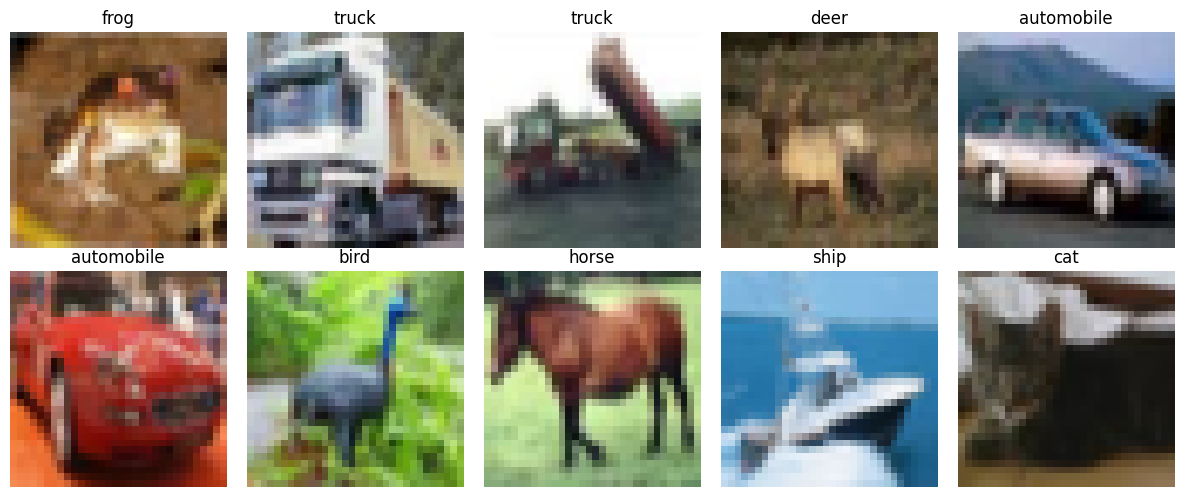

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, index in zip(axes.ravel(), range(10)):
    image, label = train_dataset[index]
    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

But : preparer toutes les images CIFAR-10 en conservant une separation train/validation/test, normaliser et encoder les labels en one-hot.

Pourquoi : utiliser tout le jeu CIFAR-10 sans utiliser le test pour l entrainement ou la selection du modele.


In [12]:
TRAIN_SAMPLES = 45_000
VALIDATION_SAMPLES = 5_000
TEST_SAMPLES = 10_000
NUM_CLASSES = 10
SEED = 42
AUGMENT_TRAINING = False
AUGMENT_MAX_SHIFT = 4
DROPOUT_RATE = 0.1
PCA_COMPONENTS = 800

rng = np.random.default_rng(SEED)

all_train_indices = rng.permutation(len(train_dataset))
train_indices = all_train_indices[:TRAIN_SAMPLES]
validation_indices = all_train_indices[TRAIN_SAMPLES:]
test_indices = np.arange(len(test_dataset))

def to_numpy_subset(dataset, indices):
    images = []
    labels = []
    for index in indices:
        image, label = dataset[index]
        images.append(np.asarray(image, dtype=np.float32) / 255.0)
        labels.append(label)
    X = np.stack(images)
    y = np.array(labels, dtype=int)
    return X, y

X_train_img, y_train_idx = to_numpy_subset(train_dataset, train_indices)
X_validation_img, y_validation_idx = to_numpy_subset(train_dataset, validation_indices)
X_test_img, y_test_idx = to_numpy_subset(test_dataset, test_indices)
if AUGMENT_TRAINING:
    X_train_img = augment_images(
        X_train_img,
        horizontal_flip=True,
        max_shift=AUGMENT_MAX_SHIFT,
        seed=SEED,
    )

X_train = X_train_img.reshape(len(X_train_img), -1)
X_validation = X_validation_img.reshape(len(X_validation_img), -1)
X_test = X_test_img.reshape(len(X_test_img), -1)

mean = X_train.mean(axis=0, keepdims=True)
std = X_train.std(axis=0, keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_validation = (X_validation - mean) / std
X_test = (X_test - mean) / std

# PCA et blanchiment ajustes uniquement sur les donnees d entrainement.
pca = PCA(
    n_components=PCA_COMPONENTS,
    whiten=True,
    svd_solver='randomized',
    random_state=SEED,
)
X_train = pca.fit_transform(X_train).astype(np.float32)
X_validation = pca.transform(X_validation).astype(np.float32)
X_test = pca.transform(X_test).astype(np.float32)

y_train = np.eye(NUM_CLASSES)[y_train_idx]
y_validation = np.eye(NUM_CLASSES)[y_validation_idx]
y_test = np.eye(NUM_CLASSES)[y_test_idx]

assert len(train_dataset) == 50_000
assert len(test_dataset) == 10_000
assert len(train_indices) == TRAIN_SAMPLES
assert len(validation_indices) == VALIDATION_SAMPLES
assert len(test_indices) == TEST_SAMPLES
assert set(train_indices).isdisjoint(validation_indices)
assert len(train_indices) + len(validation_indices) == len(train_dataset)
assert X_train.shape == (TRAIN_SAMPLES, PCA_COMPONENTS)
assert X_validation.shape == (VALIDATION_SAMPLES, PCA_COMPONENTS)
assert X_test.shape == (TEST_SAMPLES, PCA_COMPONENTS)
assert y_train.shape == (TRAIN_SAMPLES, NUM_CLASSES)
assert y_validation.shape == (VALIDATION_SAMPLES, NUM_CLASSES)
assert y_test.shape == (TEST_SAMPLES, NUM_CLASSES)
assert np.all((y_train_idx >= 0) & (y_train_idx < NUM_CLASSES))
assert np.all((y_validation_idx >= 0) & (y_validation_idx < NUM_CLASSES))
assert np.all((y_test_idx >= 0) & (y_test_idx < NUM_CLASSES))
assert np.allclose(y_train.sum(axis=1), 1.0)
assert np.allclose(y_validation.sum(axis=1), 1.0)
assert np.allclose(y_test.sum(axis=1), 1.0)

print('Verification checklist:')
print('- CIFAR-10 source sizes: 50,000 train / 10,000 test')
print('- Split: 45,000 train / 5,000 validation / 10,000 test')
print('- All CIFAR-10 training images are used exactly once in train/validation')
print('- Augmentation applied to training images only:', AUGMENT_TRAINING)
print('- PCA whitening components:', PCA_COMPONENTS)
print('- Train and validation indices are disjoint')
print('- Normalization fitted on training data only')
print('- Labels are valid one-hot vectors for 10 classes')

X_train.shape, y_train.shape, X_validation.shape, y_validation.shape, X_test.shape, y_test.shape


Verification checklist:
- CIFAR-10 source sizes: 50,000 train / 10,000 test
- Split: 45,000 train / 5,000 validation / 10,000 test
- All CIFAR-10 training images are used exactly once in train/validation
- Augmentation applied to training images only: True
- Train and validation indices are disjoint
- Normalization fitted on training data only
- Labels are valid one-hot vectors for 10 classes


((45000, 3072),
 (45000, 10),
 (5000, 3072),
 (5000, 10),
 (10000, 3072),
 (10000, 10))

**But** : tester une architecture dense inspiree de Z-LIN avec le protocole de baseline.

**Important** : cette cellule active PCA/blanchiment, l'architecture 4000-1000 alternee et le dropout 0,1. Le pre-entrainement ZAE specifique de l'article n'est pas encore implemente.


In [13]:

INPUT_DIM = PCA_COMPONENTS
NUM_CLASSES = 10
HIDDEN_UNITS = (4000, 1000, 4000, 1000, 4000, 1000, 4000)
LEARNING_RATE = 1e-3
MOMENTUM = 0.9
L2_STRENGTH = 1e-4
EPOCHS = 300
BATCH_SIZE = 100

model_layers = []
previous_dim = INPUT_DIM
for index, hidden_dim in enumerate(HIDDEN_UNITS):
    model_layers.extend([
        Dense(input_dim=previous_dim, output_dim=hidden_dim, seed=index),
        ReLU(),
        Dropout(rate=DROPOUT_RATE, seed=10 + index),
    ])
    previous_dim = hidden_dim
model_layers.extend([
    Dense(input_dim=previous_dim, output_dim=NUM_CLASSES, seed=100),
    Softmax(),
])
model = Sequential(model_layers)

dense_layers = [layer for layer in model.layers if hasattr(layer, 'input_dim')]
assert [layer.output_dim for layer in dense_layers] == (*HIDDEN_UNITS, NUM_CLASSES)
assert dense_layers[0].input_dim == INPUT_DIM

sample_output = model.forward(X_train[:8])
assert sample_output.shape == (8, NUM_CLASSES)
np.testing.assert_allclose(sample_output.sum(axis=1), 1.0, atol=1e-6)

print({
    'split': (TRAIN_SAMPLES, VALIDATION_SAMPLES, TEST_SAMPLES),
    'architecture': (INPUT_DIM, *HIDDEN_UNITS, NUM_CLASSES),
    'learning_rate': LEARNING_RATE,
    'momentum': MOMENTUM,
    'dropout_rate': DROPOUT_RATE,
    'l2_strength': L2_STRENGTH,
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
})

loss = MulticlassCrossEntropy()

optimizer = SGD(lr=LEARNING_RATE, momentum=MOMENTUM)
regularizer = L2Regularization(strength=L2_STRENGTH)
model


{'split': (45000, 5000, 10000), 'architecture': (3072, 1024, 512, 256, 10), 'learning_rate': 0.0005, 'momentum': 0.9, 'dropout_rate': 0.5, 'l2_strength': 0.0001, 'epochs': 300, 'batch_size': 100, 'seed': 42}


Sequential(layers=[Dense(input_dim=3072, output_dim=1024, seed=0, W=array([[ 0.0032, -0.0034,  0.0163, ...,  0.013 , -0.0274, -0.0085],
       [ 0.0124,  0.0412, -0.02  , ..., -0.0139,  0.0048,  0.0079],
       [ 0.0205,  0.0032,  0.0081, ..., -0.0032, -0.0112,  0.0138],
       ...,
       [-0.0043, -0.0397,  0.0152, ..., -0.0393, -0.0317,  0.0447],
       [ 0.0142,  0.0236, -0.0172, ..., -0.0057,  0.0348, -0.0538],
       [-0.0159, -0.018 , -0.0115, ...,  0.0039, -0.0561,  0.0233]],
      shape=(3072, 1024)), b=array([0., 0., 0., ..., 0., 0., 0.], shape=(1024,)), dW=array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(3072, 1024)), db=array([0., 0., 0., ..., 0., 0., 0.], shape=(1024,))), ReLU(), Dropout(rate=0.5, seed=10, training=True), Dense(input_dim=1024, output_dim=512, seed=1, W=array([[

## Configuration unique du backend

Une seule exécution est lancée : NumPy sur CPU ou CuPy sur GPU selon `BACKEND`.


In [14]:
import time

from src.core.backend import get_backend

BACKEND = 'gpu'  # Choisir 'cpu' ou 'gpu'.
backend = get_backend(BACKEND)
print({
    'backend': 'CuPy' if backend.is_gpu else 'NumPy',
    'device': 'CUDA' if backend.is_gpu else 'CPU',
    'backend_version': backend.xp.__version__,
})

model_layers = []
previous_dim = INPUT_DIM
for index, hidden_dim in enumerate(HIDDEN_UNITS):
    model_layers.extend([
        Dense(input_dim=previous_dim, output_dim=hidden_dim, seed=index, backend=backend),
        ReLU(backend=backend),
        Dropout(rate=DROPOUT_RATE, seed=10 + index, backend=backend),
    ])
    previous_dim = hidden_dim
model_layers.extend([
    Dense(input_dim=previous_dim, output_dim=NUM_CLASSES, seed=100, backend=backend),
    Softmax(backend=backend),
])
model = Sequential(model_layers)
loss = MulticlassCrossEntropy(backend=backend)
regularizer = L2Regularization(strength=L2_STRENGTH)

sample_output = model.forward(X_train[:8])
assert backend.is_array(sample_output)
assert sample_output.shape == (8, NUM_CLASSES)
probability_sums = backend.sum(sample_output, axis=1)
assert backend.scalar(probability_sums.min()) > 0.999
assert backend.scalar(probability_sums.max()) < 1.001

print({
    'split': (TRAIN_SAMPLES, VALIDATION_SAMPLES, TEST_SAMPLES),
    'architecture': (INPUT_DIM, *HIDDEN_UNITS, NUM_CLASSES),
    'learning_rate': LEARNING_RATE,
    'momentum': MOMENTUM,
    'dropout_rate': DROPOUT_RATE,
    'l2_strength': L2_STRENGTH,
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
})


{'backend': 'CuPy', 'device': 'CUDA', 'backend_version': '14.2.0'}
{'split': (45000, 5000, 10000), 'architecture': (3072, 1024, 512, 256, 10), 'learning_rate': 0.0005, 'momentum': 0.9, 'dropout_rate': 0.5, 'l2_strength': 0.0001, 'epochs': 300, 'batch_size': 100, 'seed': 42}


**But** : entraîner le modèle une seule fois avec le backend choisi.

**Pourquoi** : comparer uniquement les performances du backend explicitement sélectionné.


In [15]:
start_time = time.perf_counter()
scheduler = ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-6)
history = train_multiclass_classifier(
    model=model,
    X=X_train,
    y=y_train,
    loss=loss,
    optimizer=optimizer,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
    validation_data=(X_validation, y_validation),
    regularizer=regularizer,
    scheduler=scheduler,
)
backend.synchronize()
elapsed_seconds = time.perf_counter() - start_time

assert len(history) == EPOCHS
assert all(row.validation_loss is not None for row in history)
assert all(row.validation_accuracy is not None for row in history)
assert all(row.weight_norm is not None for row in history)
assert all(row.gradient_norm is not None for row in history)
assert all(row.relu_zero_fraction is not None for row in history)

best_epoch = history.best_epoch
best_metrics = history[best_epoch]
assert 0 <= best_epoch < EPOCHS

print({
    'backend': 'CuPy' if backend.is_gpu else 'NumPy',
    'device': 'CUDA' if backend.is_gpu else 'CPU',
    'elapsed_seconds': round(elapsed_seconds, 2),
    'best_epoch': best_epoch,
    'best_validation_loss': best_metrics.validation_loss,
    'best_validation_accuracy': best_metrics.validation_accuracy,
})


{'backend': 'CuPy', 'device': 'CUDA', 'elapsed_seconds': 2709.25, 'best_epoch': 299, 'best_validation_loss': 1.6970207438165417, 'best_validation_accuracy': 0.4094}


**But** : visualiser la loss et l'accuracy train.

**Pourquoi** : verifier la convergence du MLP avant l'evaluation finale sur le test set.


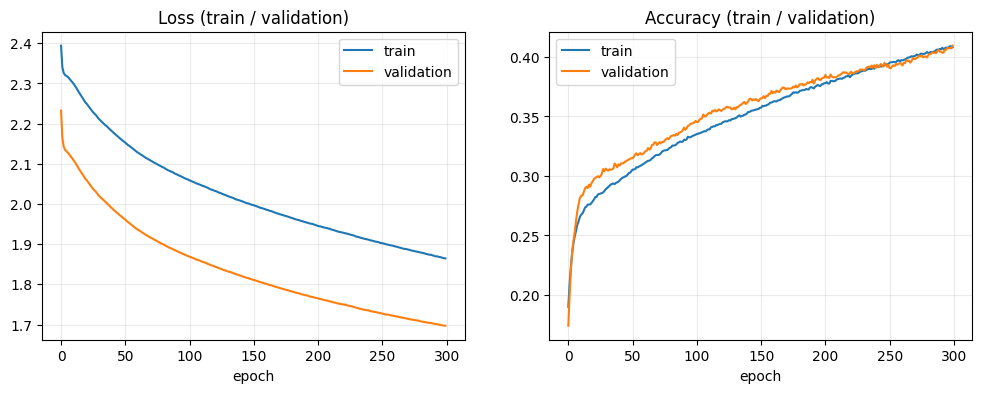

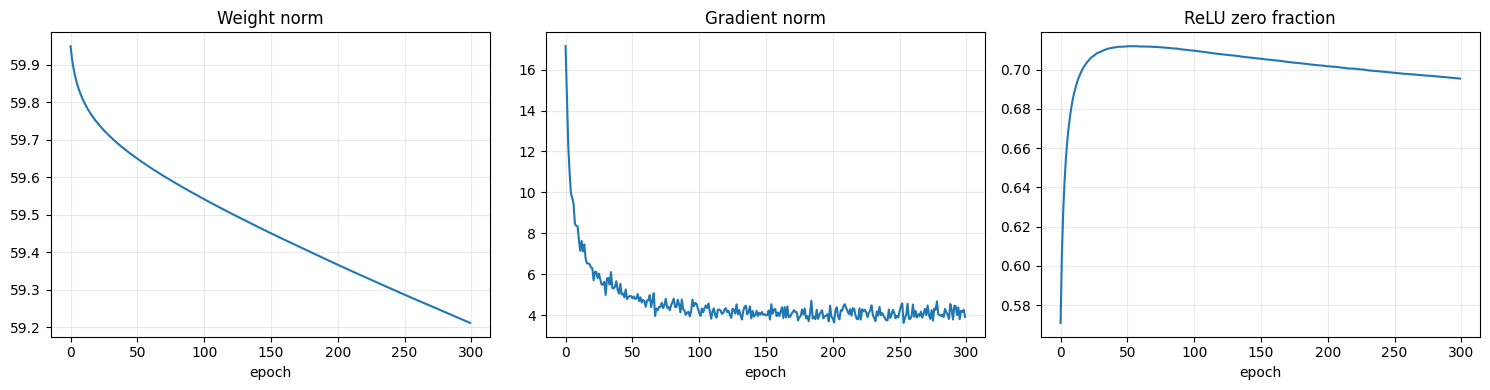

In [16]:
epochs = [row.epoch for row in history]
losses = [row.loss for row in history]
accuracies = [row.accuracy for row in history]
validation_losses = [row.validation_loss for row in history]
validation_accuracies = [row.validation_accuracy for row in history]
weight_norms = [row.weight_norm for row in history]
gradient_norms = [row.gradient_norm for row in history]
relu_zero_fractions = [row.relu_zero_fraction for row in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, losses)
axes[0].plot(epochs, validation_losses)
axes[0].legend(['train', 'validation'])
axes[0].set_title('Loss (train / validation)')
axes[0].set_xlabel('epoch')
axes[0].grid(True, alpha=0.25)

axes[1].plot(epochs, accuracies)
axes[1].plot(epochs, validation_accuracies)
axes[1].legend(['train', 'validation'])
axes[1].set_title('Accuracy (train / validation)')
axes[1].set_xlabel('epoch')
axes[1].grid(True, alpha=0.25)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epochs, weight_norms)
axes[0].set_title('Weight norm')
axes[1].plot(epochs, gradient_norms)
axes[1].set_title('Gradient norm')
axes[2].plot(epochs, relu_zero_fractions)
axes[2].set_title('ReLU zero fraction')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


**But** : evaluer le modele sur le test set.

**Pourquoi** : mesurer la generalisation reelle du MLP from scratch sur CIFAR-10.


In [17]:
# Evaluation finale sur le test set, sans selectionner de modele avec le test.
from src.metrics import multiclass_accuracy

test_probs = model.predict_proba(X_test)
test_acc = multiclass_accuracy(y_test, test_probs, backend=backend)
test_pred_idx = backend.to_host(backend.argmax(test_probs, axis=1))
test_true_idx = np.argmax(y_test, axis=1)
test_probs = backend.to_host(test_probs)

print('Final held-out test accuracy =', round(test_acc, 4))
print('Test set was not used for epoch or hyperparameter selection.')
print('Reported model: final training epoch; best validation epoch is reported above.')


Final held-out test accuracy = 0.4096
Test set was not used for epoch or hyperparameter selection.
Reported model: final training epoch; best validation epoch is reported above.


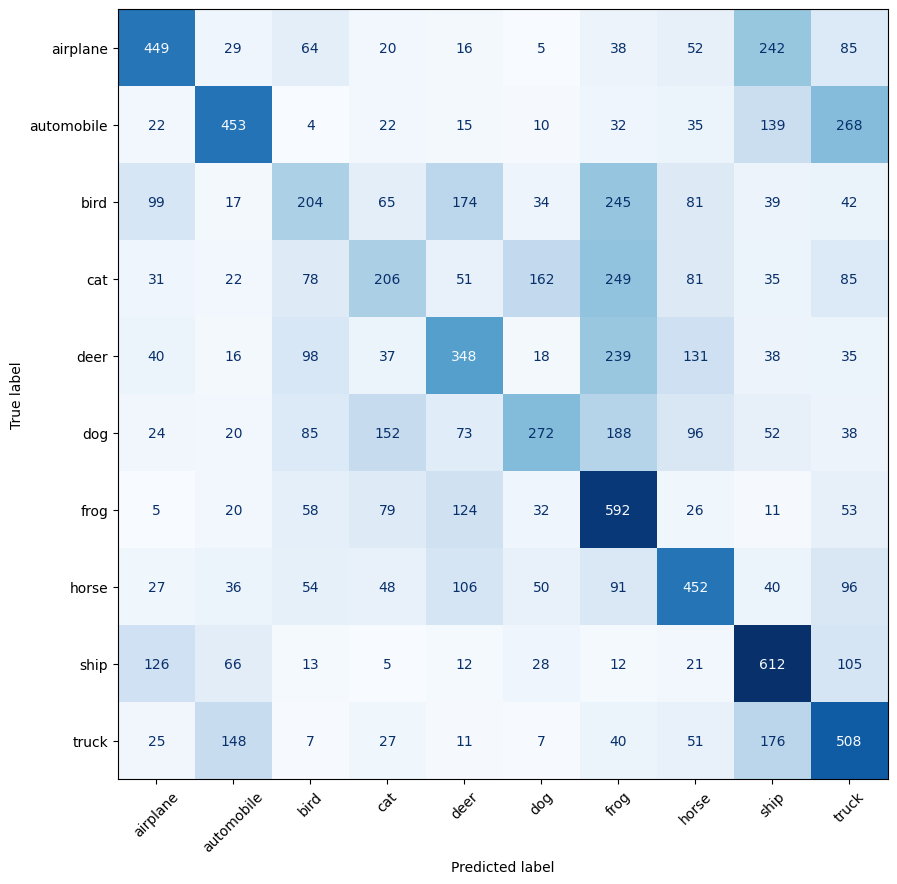

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(test_true_idx, test_pred_idx)
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.show()

### Comparaison finale CPU / GPU

Le test est évalué après la sélection par validation.


In [19]:
# Evaluation finale sur le test set, après la sélection par validation.
test_metrics = evaluate_multiclass(model, X_test, y_test, loss)
print({
    'backend': 'CuPy' if backend.is_gpu else 'NumPy',
    'device': 'CUDA' if backend.is_gpu else 'CPU',
    'test_loss': test_metrics.loss,
    'test_accuracy': test_metrics.accuracy,
})
print('Le test n’a pas été utilisé pour sélectionner le modèle.')


NameError: name 'evaluate_multiclass' is not defined

**But** : afficher la matrice de confusion.

**Pourquoi** : voir quelles classes le MLP confond le plus.
